# Game of Thrones - Network Analysis
### Who Really Matters in Westeros?

The network represents interactions among characters in *A Song of Ice and Fire*. Nodes are characters, edges are interactions and edge weights indicate interaction frequency. Use the five-book aggregated graph prepared below. Unless explicitly stated otherwise, calculate centrality and shortest paths on the unweighted graph.

Write your own code and explanations. Standard NetworkX measures are allowed; the functions in Task 3 must be your own. Include plots, executed outputs and written answers. The provided tests show input/output conventions; add at least one meaningful test of your own, including a boundary or nontrivial case.

In [ ]:
%pip install networkx

## Data preparation

The following setup follows the data-loading approach used in the course notebooks. Run these cells before starting the assignment.

Graph with 796 nodes and 2823 edges


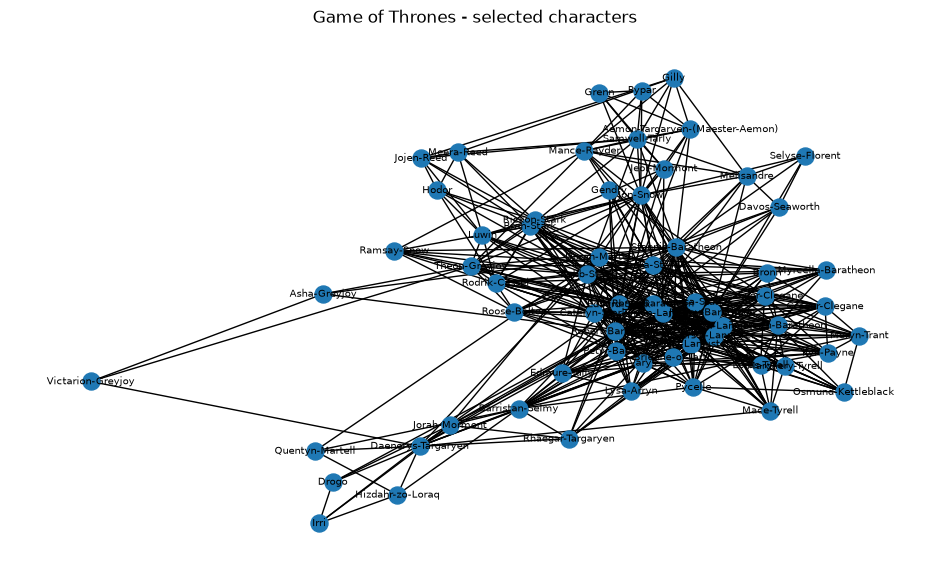

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

%matplotlib inline
# Same five-book data preparation as in the original Game of Thrones assignment.
books = []
for i in range(5):
    books.append(pd.read_csv('data/asoiaf-book{}-edges.csv'.format(i + 1)))

all_books = pd.concat(books)
edges = all_books.groupby(['Source', 'Target']).agg({'weight': 'sum'}).reset_index()
GOT = nx.from_pandas_edgelist(edges, source='Source', target='Target', edge_attr='weight')
print(GOT)

# As in the course notebook, inspect a subnetwork of frequently interacting characters.
weighted_degrees = dict(GOT.degree(weight='weight'))
subG = GOT.subgraph([node for node in weighted_degrees if weighted_degrees[node] > 200]).copy()
pos = nx.spring_layout(subG, weight='weight', seed=42)
plt.figure(figsize=(12, 7))
nx.draw_networkx(subG, pos, node_size=150, font_size=7, with_labels=True)
plt.title('Game of Thrones - selected characters')
plt.axis('off')
plt.show()

# Use GOT (the FULL aggregated network) for all graded tasks below.
G = GOT


## Task 1 (2 pts)

Report the number of nodes and edges, density, and number of connected components. Find the largest connected component and calculate its diameter and average shortest path length. Visualize the network and highlight its most connected characters. **Explain:** What do these properties suggest about the structure of relationships?

In [24]:
# Your analysis here
node_count = G.number_of_nodes()
print(f"Number of nodes: {node_count}")

edge_count = G.number_of_edges()
print(f"Number of nodes: {edge_count}")

density = nx.density(G)
print(f"Density {density}")

connected_components_count = nx.number_connected_components(G)
print(f"Number of connected components: {connected_components_count}")

connected_component_nodes = nx.connected_components(G)
largest_connected_component_nodes = max(connected_component_nodes, key=len)
largest_connected_component = G.subgraph(largest_connected_component_nodes).copy()
print(f"Number of largest connected component nodes: {len(largest_connected_component)}")

diameter = nx.diameter(largest_connected_component)
print(f"Diameter: {diameter}")

avg_shortest_path_length = nx.average_shortest_path_length(largest_connected_component)
print(f"Average shortest path length: {avg_shortest_path_length}")


Number of nodes: 796
Number of nodes: 2823
Density 0.008921968332227173
Number of connected components: 1
Number of largest connected component nodes: 796
Diameter: 9
Average shortest path length: 3.416225783003066


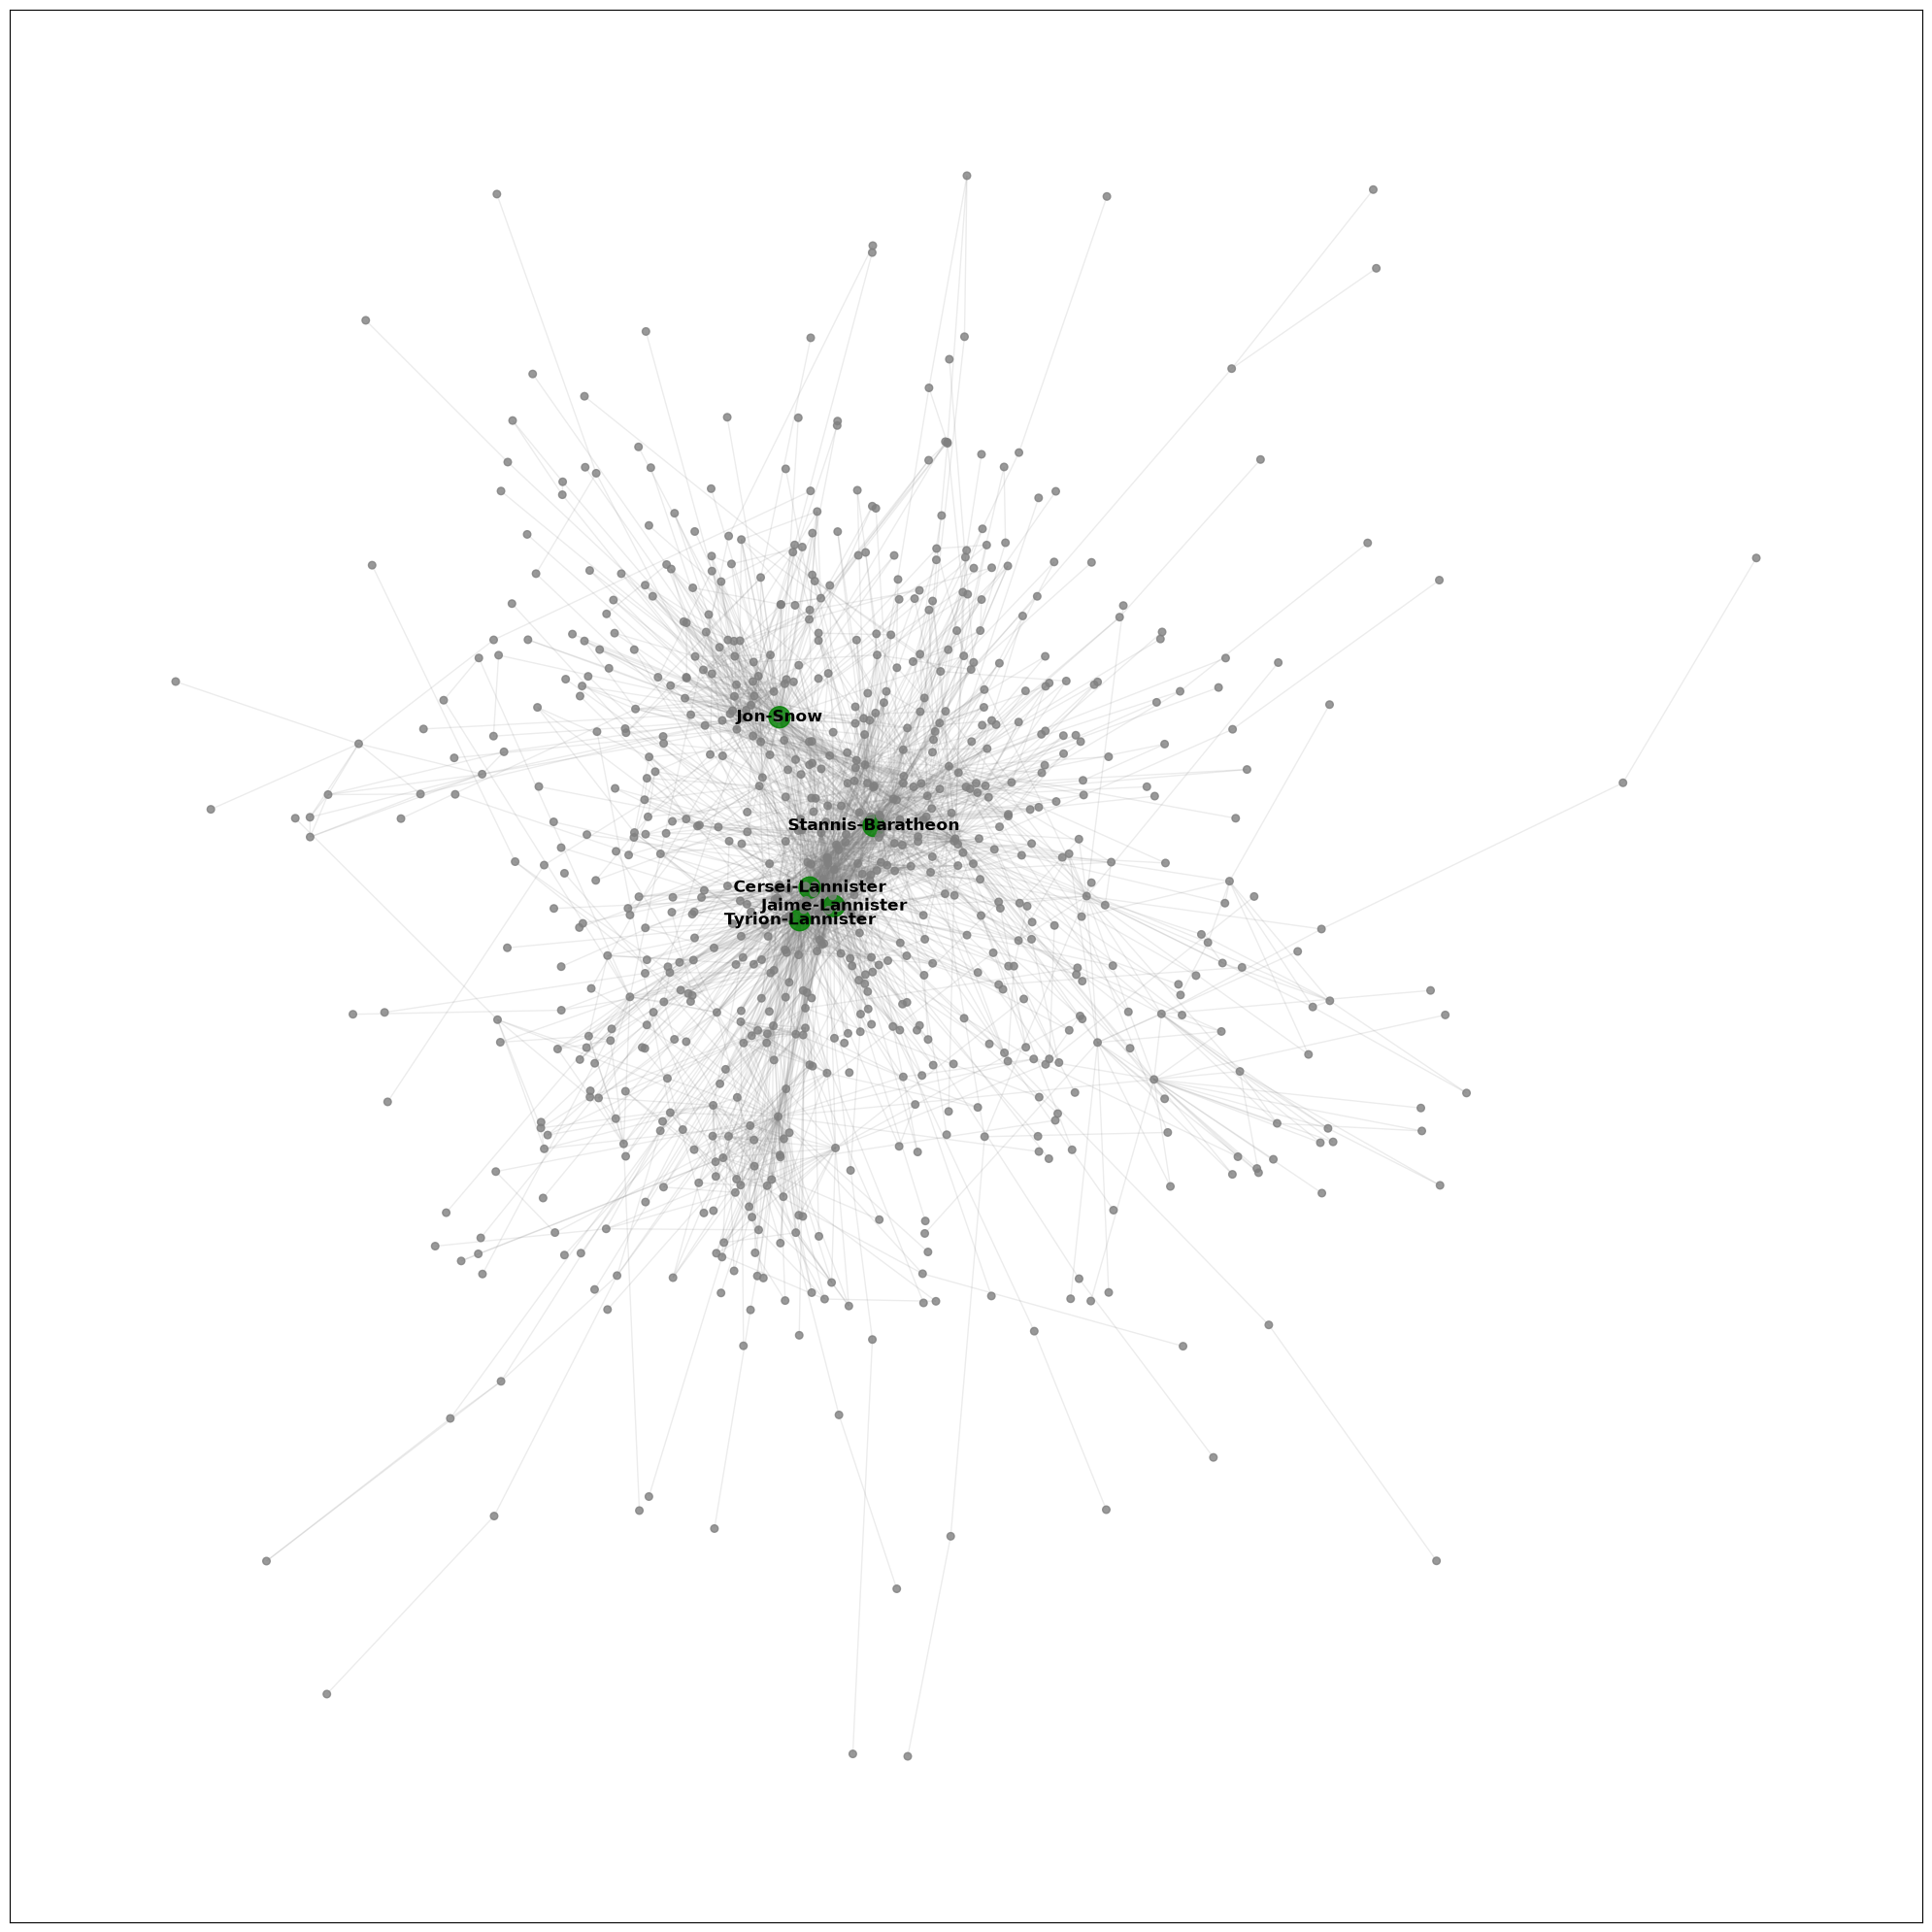

In [23]:
NUMEBER_OF_MOST_CONNECTED_CHARACTERS = 5
most_connected_characters = [node for node, deg in sorted(G.degree(), key=lambda x: (-x[1], x[0]))[:NUMEBER_OF_MOST_CONNECTED_CHARACTERS]]

pos = nx.spring_layout(G, seed=42)
node_colors = ['green' if node in set(most_connected_characters) else 'gray' for node in G.nodes()]
node_sizes = [250 if node in set(most_connected_characters) else 30 for node in G.nodes()]


plt.figure(figsize=(20, 20))
nx.draw_networkx_edges(G, pos, alpha=0.15, edge_color='gray')
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, alpha=0.8)
nx.draw_networkx_labels(G, pos, labels={n: n for n in most_connected_characters}, font_size=12, font_weight='bold')

plt.tight_layout()
plt.show()

## Task 2 (2 pts)

Calculate degree, closeness and betweenness centrality (unweighted). Present the top 10 characters for each measure in a table. Identify characters appearing in all three top-10 lists. **Explain:** Are the most connected characters necessarily the most important intermediaries? Why can the three rankings differ? Break ties alphabetically so that every ranking is deterministic.

In [ ]:
# Your centrality calculations and comparison here


## Task 3 (3 pts)

Implement **both** functions without ready-made ranking comparison/correlation functions:

- `ranking_overlap(ranking1, ranking2, k)` - fraction of identifiers shared by the first `k` positions of both rankings. **1 point** for the implementation.
- `spearman_rank_correlation(ranking1, ranking2)` - Spearman rank correlation using the rank-difference formula, with no `scipy.stats.spearmanr` or equivalent. **1 point** for the implementation.
- **1 point** for meaningful tests of the functions, including a nontrivial or boundary case.

Both rankings are sequences containing the same unique character identifiers. Use the complete rankings for Spearman. You may assume valid inputs with no duplicate identifiers; tied centrality scores must have been resolved alphabetically before constructing the rankings. The scaffold below provides steps, not the solution.

In [ ]:
def ranking_overlap(ranking1, ranking2, k):
    # Step 1 - take the first k identifiers from each ranking.
    # Step 2 - find the identifiers appearing in both top-k groups.
    # Step 3 - return the fraction relative to k.
    raise NotImplementedError

def spearman_rank_correlation(ranking1, ranking2):
    # Step 1 - build a mapping from each character to its position in ranking2.
    # Step 2 - for each character in ranking1, calculate the difference in ranks.
    # Step 3 - sum the squared differences.
    # Step 4 - apply the Spearman rank-difference formula and return the result.
    # Assumptions - same unique identifiers in both rankings, no unresolved ties.
    raise NotImplementedError

### Provided function checks

These checks show the expected input and output formats. They do **not** replace your own tests. Run them after completing Task 3.

In [ ]:
# Provided checks - run after implementing both functions.
# Add at least one test of your own and explain its expected result.
assert ranking_overlap(["A", "B", "C", "D", "E"], ["C", "D", "E", "A", "B"], 2) == 0.0
assert ranking_overlap(["A", "B", "C", "D", "E"], ["C", "D", "E", "A", "B"], 5) == 1.0
assert abs(spearman_rank_correlation(["A", "B", "C"], ["A", "B", "C"]) - 1.0) < 1e-12
assert abs(spearman_rank_correlation(["A", "B", "C"], ["C", "B", "A"]) + 1.0) < 1e-12
print("Provided checks passed")

## Task 4 (2 pts)

For each pair of centrality measures, calculate top-5 and top-10 overlap and Spearman correlation over the complete rankings. Display the results in a table and an appropriate plot (e.g., heatmap). Identify the most similar pair. **Explain:** Does high top-k overlap imply strong agreement across the full rankings?

In [ ]:
# Your experiment and visualization here


## Task 5 (1 pts)

**Who is the most important character in this network?** Give a justified answer using at least two definitions of importance and numerical evidence. Discuss one limitation of your interpretation.

In [ ]:
# Write your final conclusions in a new Markdown cell below this cell.